In [3]:
import rasterio
import numpy as np

# 라벨 파일 하나 경로 지정
label_path = "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Training/02.라벨링데이터/TL_SN10/SN10_CHN_00001_230409.tif"

with rasterio.open(label_path) as src:
    label = src.read(1)   # 단일 채널 읽기

print("라벨 shape:", label.shape)
print("라벨 고유값:", np.unique(label))

라벨 shape: (512, 512)
라벨 고유값: [10 90]


In [4]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import jaccard_score
import rasterio

# ======================
# 1. 데이터셋 정의
# ======================
# class IndustrialDataset(Dataset):
#     def __init__(self, img_dir, label_dir):
#         self.img_dir = img_dir
#         self.label_dir = label_dir
#         # 두 폴더에서 공통되는 파일명만 추출
#         self.img_files = sorted(os.listdir(img_dir))
#         self.label_files = sorted(os.listdir(label_dir))

#         # 공통 이름 매칭
#         self.file_names = [f for f in self.img_files if f in self.label_files]

#     def __len__(self):
#         return len(self.file_names)

#     def __getitem__(self, idx):
#         fname = self.file_names[idx]
#         img_path = os.path.join(self.img_dir, fname)
#         label_path = os.path.join(self.label_dir, fname)

#         # Sentinel-2 원천 데이터 읽기 (4채널)
#         with rasterio.open(img_path) as src:
#             img = src.read().astype(np.float32)   # (4, H, W)

#         # 라벨 데이터 읽기 (단일 채널)
#         with rasterio.open(label_path) as src:
#             label = src.read(1).astype(np.int64)  # (H, W)

#         # 정규화
#         img = img / 10000.0

#         return torch.tensor(img, dtype=torch.float32), torch.tensor(label, dtype=torch.long)
class IndustrialDataset(Dataset):
    def __init__(self, img_dir, label_dir):
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.label_files = sorted(os.listdir(label_dir))
        self.file_names = [f for f in self.img_files if f in self.label_files]

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        fname = self.file_names[idx]
        img_path = os.path.join(self.img_dir, fname)
        label_path = os.path.join(self.label_dir, fname)

        # Sentinel-2 원천 데이터 읽기 (4채널)
        with rasterio.open(img_path) as src:
            img = src.read().astype(np.float32)

        # 라벨 데이터 읽기
        with rasterio.open(label_path) as src:
            label = src.read(1).astype(np.int64)

        # 라벨 값 매핑 (10 → 0, 90 → 1)
        label = np.where(label == 90, 1, 0).astype(np.int64)

        # 입력 정규화
        img = img / 10000.0

        return torch.tensor(img, dtype=torch.float32), torch.tensor(label, dtype=torch.long)
    

# ======================
# 2. U-Net 모델 정의
# ======================
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(DoubleConv, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class UNet(nn.Module):
    def __init__(self, n_channels, n_classes):
        super(UNet, self).__init__()
        self.enc1 = DoubleConv(n_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(2)

        self.up1 = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec1 = DoubleConv(512, 256)
        self.up2 = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = DoubleConv(256, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec3 = DoubleConv(128, 64)

        self.final = nn.Conv2d(64, n_classes, kernel_size=1)

    def forward(self, x):
        c1 = self.enc1(x)
        c2 = self.enc2(self.pool(c1))
        c3 = self.enc3(self.pool(c2))
        c4 = self.enc4(self.pool(c3))

        u1 = self.up1(c4)
        d1 = self.dec1(torch.cat([u1, c3], dim=1))
        u2 = self.up2(d1)
        d2 = self.dec2(torch.cat([u2, c2], dim=1))
        u3 = self.up3(d2)
        d3 = self.dec3(torch.cat([u3, c1], dim=1))

        return self.final(d3)


# ======================
# 3. 학습 준비
# ======================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dataset = IndustrialDataset(
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_SN10_SN10",
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Training/02.라벨링데이터/TL_SN10"
)

val_dataset = IndustrialDataset(
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Validation/01.원천데이터/VS_SN10_SN10",
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Validation/02.라벨링데이터/VL_SN10"
)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

if torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using device: MPS (Apple GPU)")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using device: CUDA")
else:
    device = torch.device("cpu")
    print("Using device: CPU")

# 모델과 optimizer 초기화
model = UNet(n_channels=4, n_classes=2).to(device, dtype=torch.float32)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# ======================
# 4. 학습 루프 (mIoU 평가 포함)
# ======================
def miou(preds, labels, num_classes=2):
    preds = torch.argmax(preds, dim=1).cpu().numpy().flatten()
    labels = labels.cpu().numpy().flatten()
    return jaccard_score(labels, preds, average="macro")

EPOCHS = 10
for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for imgs, labels in train_loader:
        imgs = imgs.to(device, dtype=torch.float32)      # MPS 호환
        labels = labels.to(device, dtype=torch.long)

        optimizer.zero_grad() 
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    # Validation
    model.eval()
    val_miou = 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs = imgs.to(device, dtype=torch.float32)
            labels = labels.to(device, dtype=torch.long)
            outputs = model(imgs)
            val_miou += miou(outputs, labels)

    print(f"Epoch [{epoch+1}/{EPOCHS}] "
          f"Loss: {train_loss/len(train_loader):.4f} "
          f"Val mIoU: {val_miou/len(val_loader):.4f}")

# ======================
# 5. 최종 저장
# ======================
torch.save(model.state_dict(), "industrial_unet.pth")

Using device: MPS (Apple GPU)


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

Epoch [1/10] Loss: 0.1953 Val mIoU: 0.7151


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

Epoch [2/10] Loss: 0.1363 Val mIoU: 0.8258


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

... (11 outputs left out)

/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

Epoch [9/10] Loss: 0.0559 Val mIoU: 0.9126


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

Epoch [10/10] Loss: 0.0499 Val mIoU: 0.9062


## 디벨롭 

- ResNet backbone을 가진 encoder-decoder 구조
- 입력 다양성 늘림 

In [7]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import jaccard_score
import rasterio
from torchvision import models, transforms
from PIL import Image

# =======================================================
# 1️⃣ 데이터셋 정의 + 라벨 자동 리사이즈 추가
# =======================================================
class IndustrialDataset(Dataset):
    def __init__(self, img_dir, label_dir, transform=None, target_size=(256, 256)):
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.img_files = sorted(os.listdir(img_dir))
        self.label_files = sorted(os.listdir(label_dir))
        self.file_names = [f for f in self.img_files if f in self.label_files]
        self.transform = transform
        self.target_size = target_size

    def __len__(self):
        return len(self.file_names)

    def __getitem__(self, idx):
        fname = self.file_names[idx]
        img_path = os.path.join(self.img_dir, fname)
        label_path = os.path.join(self.label_dir, fname)

        # Sentinel-2 원천 데이터 (4채널)
        with rasterio.open(img_path) as src:
            img = src.read().astype(np.float32)  # (4, H, W)
        img = img / 10000.0
        img = np.transpose(img, (1, 2, 0))  # (H, W, C)

        # 라벨 데이터 읽기
        with rasterio.open(label_path) as src:
            label = src.read(1).astype(np.int64)
        label = np.where(label == 90, 1, 0).astype(np.int64)

        # 크기 맞추기
        img = Image.fromarray((img * 255).astype(np.uint8)).resize(self.target_size, Image.BILINEAR)
        # label = Image.fromarray(label).resize(self.target_size, Image.NEAREST)
        label = Image.fromarray(label.astype(np.uint8)).resize(self.target_size, Image.NEAREST)

        img = np.array(img).astype(np.float32) / 255.0
        label = np.array(label).astype(np.int64)

        if self.transform:
            img = self.transform(Image.fromarray((img * 255).astype(np.uint8)))
            img = np.array(img).astype(np.float32) / 255.0

        img = np.transpose(img, (2, 0, 1))  # (C, H, W)
        return torch.tensor(img, dtype=torch.float32), torch.tensor(label, dtype=torch.long)


# =======================================================
# 2️⃣ ResNet 기반 Encoder-Decoder (ResUNet)
# =======================================================
class ResNetUNet(nn.Module):
    def __init__(self, n_channels=4, n_classes=2):
        super().__init__()
        base_model = models.resnet34(pretrained=True)
        self.base_layers = list(base_model.children())

        # 4채널 입력
        self.base_layers[0] = nn.Conv2d(
            n_channels, 64, kernel_size=7, stride=2, padding=3, bias=False
        )

        self.encoder1 = nn.Sequential(*self.base_layers[:3])
        self.encoder2 = nn.Sequential(*self.base_layers[3:5])
        self.encoder3 = self.base_layers[5]
        self.encoder4 = self.base_layers[6]
        self.encoder5 = self.base_layers[7]

        self.up1 = self._upsample(512, 256)
        self.up2 = self._upsample(256, 128)
        self.up3 = self._upsample(128, 64)
        self.up4 = self._upsample(64, 64)

        # 최종 업샘플 추가로 (512→512 복원)
        self.up_final = nn.Sequential(
            nn.ConvTranspose2d(64, 64, kernel_size=2, stride=2),
            nn.ReLU(inplace=True)
        )
        self.final = nn.Conv2d(64, n_classes, kernel_size=1)

    def _upsample(self, in_channels, out_channels):
        return nn.Sequential(
            nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        x1 = self.encoder1(x)
        x2 = self.encoder2(x1)
        x3 = self.encoder3(x2)
        x4 = self.encoder4(x3)
        x5 = self.encoder5(x4)

        u1 = self.up1(x5) + x4
        u2 = self.up2(u1) + x3
        u3 = self.up3(u2) + x2
        u4 = self.up4(u3) + x1
        u5 = self.up_final(u4)

        return self.final(u5)


# =======================================================
# 3️⃣ 학습 설정
# =======================================================
device = torch.device("mps" if torch.backends.mps.is_available() else
                      "cuda" if torch.cuda.is_available() else "cpu")

print(f"✅ Using device: {device}")

train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3)
])

train_dataset = IndustrialDataset(
    # "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_SN10_SN10",
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Training/01.원천데이터/TS_SN10_SN10",
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Training/02.라벨링데이터/TL_SN10",
    transform=train_transform
)

val_dataset = IndustrialDataset(
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Validation/01.원천데이터/VS_SN10_SN10",
    "53.대기오염 배출원 공간 분포 데이터/3.개방데이터/1.데이터/Validation/02.라벨링데이터/VL_SN10"
)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False)

model = ResNetUNet(n_channels=4, n_classes=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


# =======================================================
# 4️⃣ mIoU + EarlyStopping
# =======================================================
def miou(preds, labels, num_classes=2):
    preds = torch.argmax(preds, dim=1).cpu().numpy().flatten()
    labels = labels.cpu().numpy().flatten()
    return jaccard_score(labels, preds, average="macro")

EPOCHS = 30
patience = 5
best_miou = 0
early_stop_counter = 0

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_miou = 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            val_miou += miou(outputs, labels)

    val_miou /= len(val_loader)
    avg_loss = train_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{EPOCHS}] Loss: {avg_loss:.4f} | Val mIoU: {val_miou:.4f}")

    if val_miou > best_miou:
        best_miou = val_miou
        early_stop_counter = 0
        torch.save(model.state_dict(), "best_resunet_fixed.pth")
        print(f"💾 Model saved! (mIoU={val_miou:.4f})")
    else:
        early_stop_counter += 1
        if early_stop_counter >= patience:
            print("⏹ Early stopping triggered!")
            break

print(f"✅ Training finished. Best mIoU = {best_miou:.4f}")

✅ Using device: mps


/Users/guns/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Users/guns/Library/Python/3.9/lib/python/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet34_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet34_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: 

Epoch [1/30] Loss: 0.4403 | Val mIoU: 0.4136
💾 Model saved! (mIoU=0.4136)


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

Epoch [2/30] Loss: 0.4191 | Val mIoU: 0.4532
💾 Model saved! (mIoU=0.4532)


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

... (52 outputs left out)

Epoch [29/30] Loss: 0.2070 | Val mIoU: 0.7468


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

Epoch [30/30] Loss: 0.2008 | Val mIoU: 0.7491
💾 Model saved! (mIoU=0.7491)
✅ Training finished. Best mIoU = 0.7491


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


In [8]:
# ======================
# 6. 최종 평가
# ======================
model.eval()
all_miou = []
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        all_miou.append(miou(outputs, labels))

print("최종 Validation mIoU:", np.mean(all_miou))

/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetRea

최종 Validation mIoU: 0.7490905781945196


/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)
/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


# 예측 시각화

In [9]:
import matplotlib.pyplot as plt
import platform

plt.rcParams['axes.unicode_minus'] = False  # 마이너스(-) 깨짐 방지

if platform.system() == 'Darwin':   # MacOS
    plt.rcParams['font.family'] = 'AppleGothic'
elif platform.system() == 'Windows': # 윈도우
    plt.rcParams['font.family'] = 'Malgun Gothic'
else: # 리눅스(Colab 등)
    plt.rcParams['font.family'] = 'NanumGothic'

/Users/guns/Library/Python/3.9/lib/python/site-packages/rasterio/__init__.py:356: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, **kwargs)


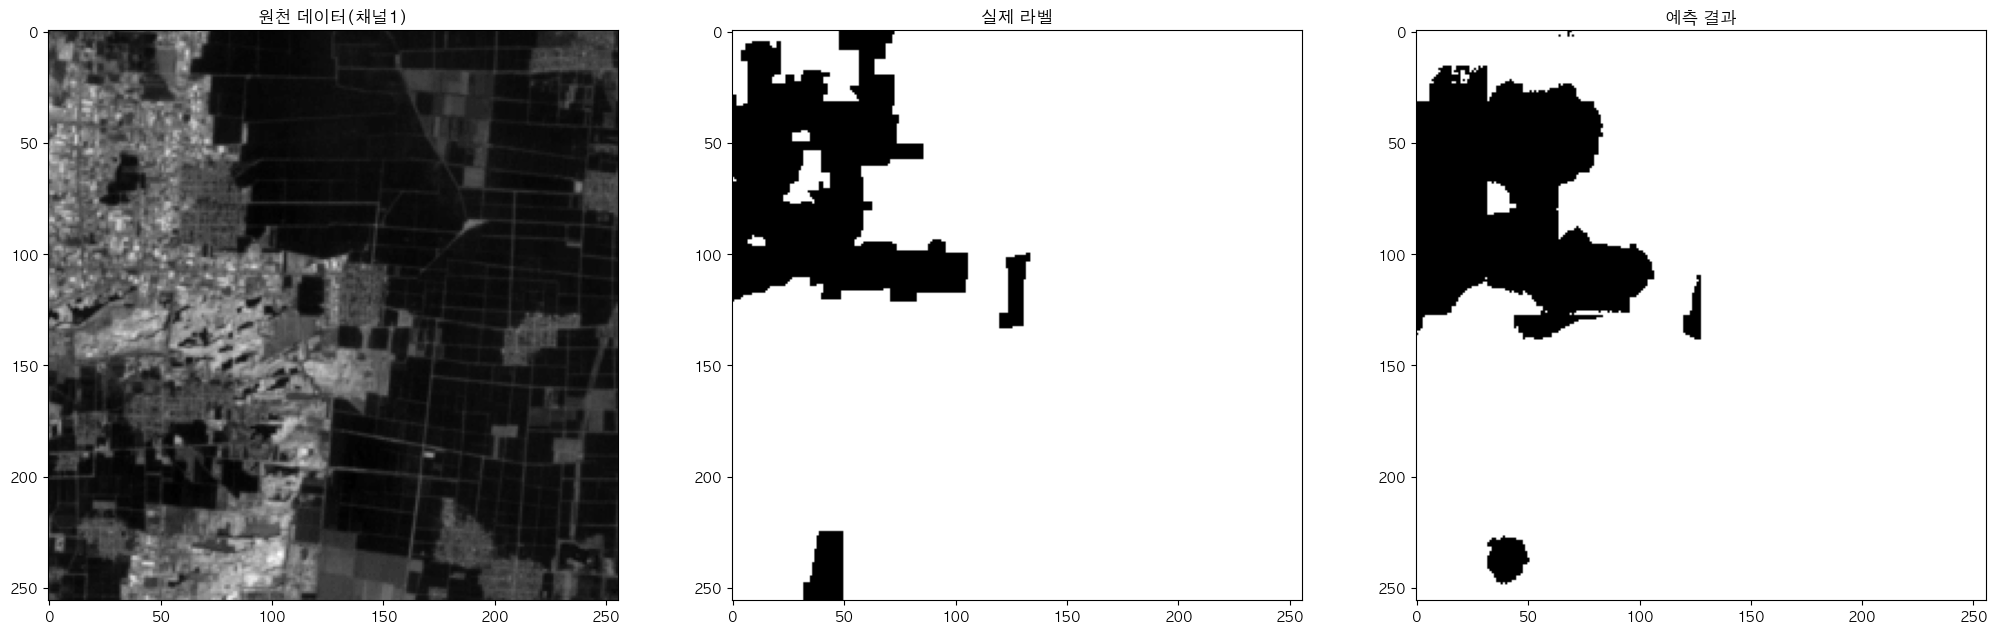

In [10]:
import matplotlib.pyplot as plt

# 검증 데이터에서 샘플 하나 가져오기
model.eval()
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)  # (B, H, W)
        break  # 첫 배치만 확인

# CPU로 변환
img_sample = imgs[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)
label_sample = labels[0].cpu().numpy()
pred_sample = preds[0].cpu().numpy()

# 시각화
plt.figure(figsize=(25,15))
plt.subplot(1,3,1)
plt.title("원천 데이터(채널1)")
plt.imshow(img_sample[:,:,0], cmap="gray")

plt.subplot(1,3,2)
plt.title("실제 라벨")
plt.imshow(label_sample, cmap="gray")

plt.subplot(1,3,3)
plt.title("예측 결과")
plt.imshow(pred_sample, cmap="gray")
plt.show()

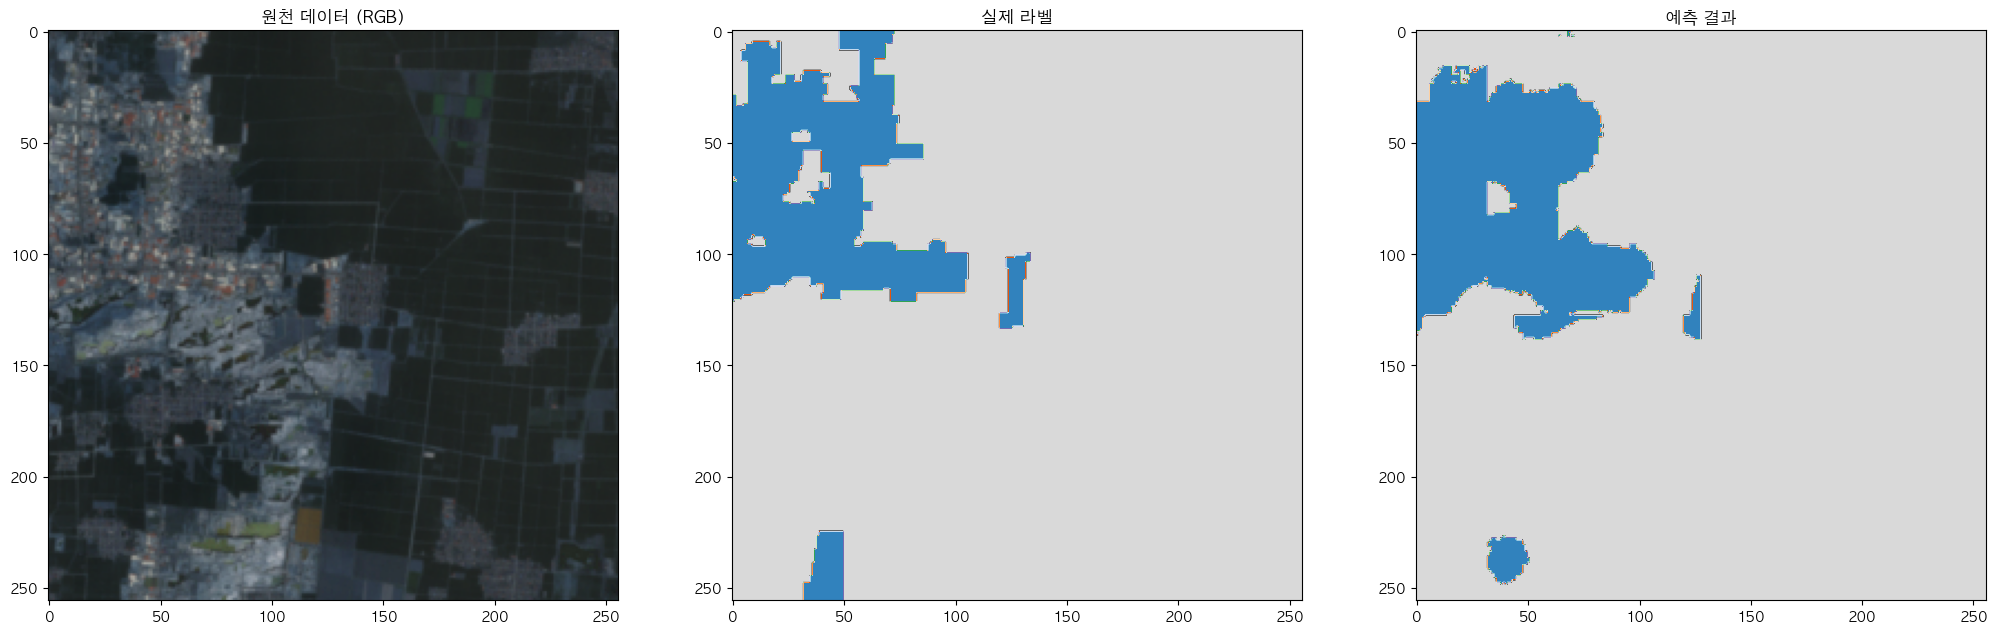

In [11]:
import matplotlib.pyplot as plt

# 검증 데이터에서 샘플 하나 가져오기
model.eval()
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)  # (B, H, W)
        break  # 첫 배치만 확인

# CPU로 변환
img_sample = imgs[0].cpu().numpy().transpose(1, 2, 0)  # (H, W, C)
label_sample = labels[0].cpu().numpy()
pred_sample = preds[0].cpu().numpy()

# ======================
# 시각화 (컬러 RGB로 표시)
# ======================
plt.figure(figsize=(25,15))

# 원천 데이터 (RGB 조합)
plt.subplot(1,3,1)
plt.title("원천 데이터 (RGB)")
rgb_img = img_sample[:,:, [2,1,0]]  # R=Band3, G=Band2, B=Band1
rgb_img = np.clip(rgb_img, 0, 1)    # 정규화 범위 맞춤
plt.imshow(rgb_img)

# 실제 라벨
plt.subplot(1,3,2)
plt.title("실제 라벨")
plt.imshow(label_sample, cmap="tab20c")  # 범주형 라벨용 색상 맵

# 예측 결과
plt.subplot(1,3,3)
plt.title("예측 결과")
plt.imshow(pred_sample, cmap="tab20c")

plt.show()

# 원하는 샘플 보기

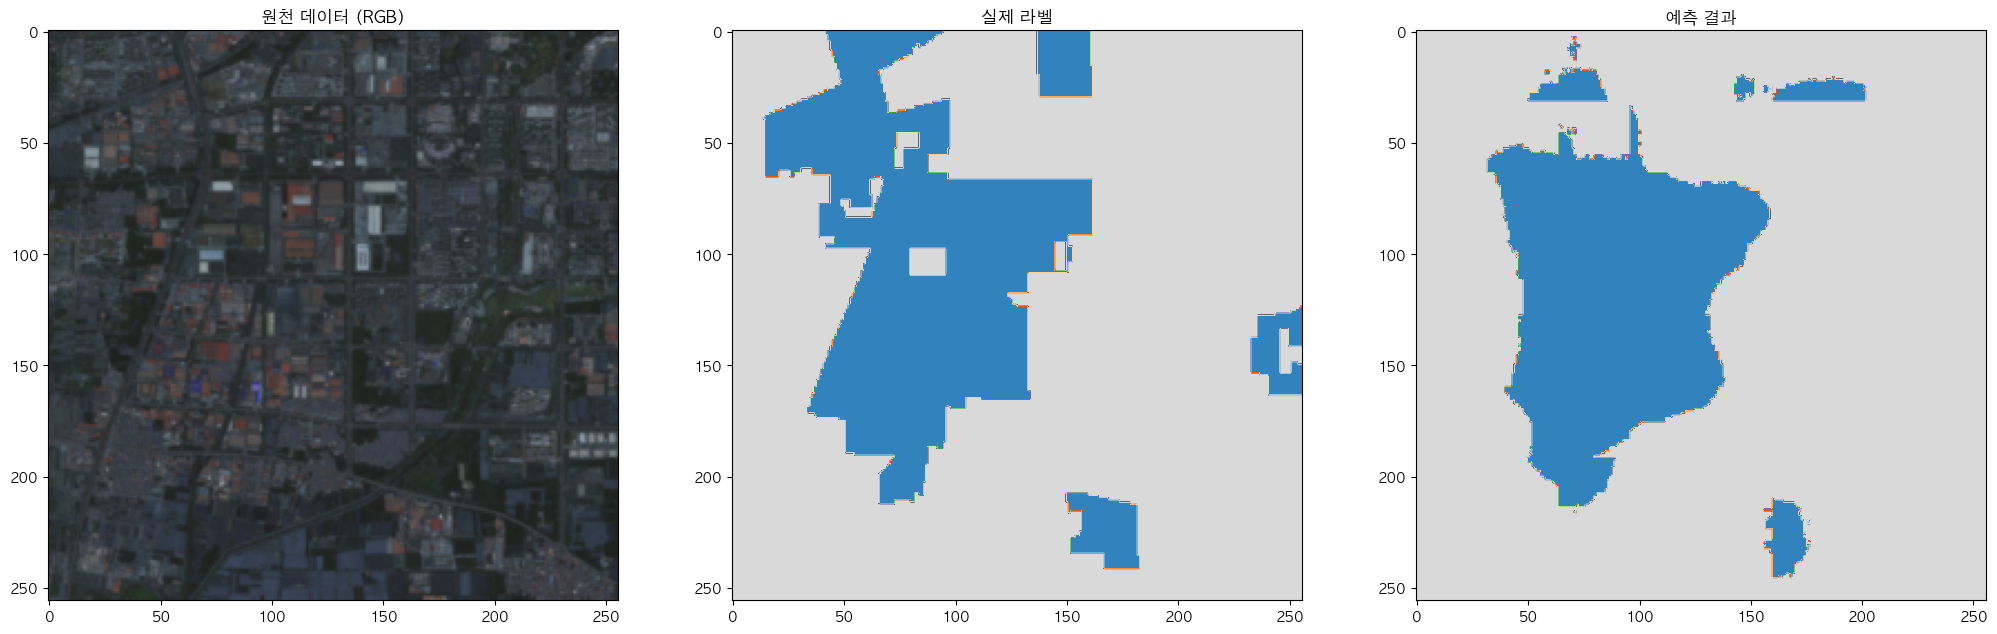

In [12]:
idx = 15  # 보고 싶은 샘플 번호
img, label = val_dataset[idx]

# 배치 차원 추가해서 모델 입력
model.eval()
with torch.no_grad():
    output = model(img.unsqueeze(0).to(device, dtype=torch.float32))
    pred = torch.argmax(output, dim=1).squeeze().cpu().numpy()

# numpy 변환
img_sample = img.numpy().transpose(1, 2, 0)  # (H, W, C)
label_sample = label.numpy()
pred_sample = pred

# 시각화
plt.figure(figsize=(25,15))
plt.subplot(1,3,1)
plt.title("원천 데이터 (RGB)")
rgb_img = np.clip(img_sample[:,:, [2,1,0]], 0, 1)
plt.imshow(rgb_img)

plt.subplot(1,3,2)
plt.title("실제 라벨")
plt.imshow(label_sample, cmap="tab20c")

plt.subplot(1,3,3)
plt.title("예측 결과")
plt.imshow(pred_sample, cmap="tab20c")
plt.show()